# Stock price forecasting using LOB

### Import modules

In [1]:
import time 
import pandas
import random
import json, argparse

# ML
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from plotly.subplots import make_subplots
from plotly import graph_objects as go
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, roc_auc_score, mean_absolute_percentage_error, root_mean_squared_error

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import models_regression as Models
import utils
import dataset as Dataset

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cuda:0


## Multi Horizon Regression:

In [3]:
dataset = pd.read_parquet('/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/Data/FI-2010-Cleaned/NoAuction/Zscore/WRT1V.parquet')
dataset = dataset.drop(['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100', 'Day'], axis=1)
dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
dataset = dataset.astype(float)
dataset = dataset.head(100000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.349285,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1.241302
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,1.326816,-0.316930,1.325949,-0.007630,1.326211,-0.449060,1.325580,-0.646518,1.325653,-0.796965,...,-0.582431,1.325328,-0.458368,1.322656,-0.206374,1.323444,-0.397135,1.324398,-0.483234,1.326383
99996,1.326816,-0.316930,1.325949,0.115155,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.590642,1.325328,-0.458368,1.326670,-0.518637,1.323444,-0.397135,1.325403,-0.230280,1.326383
99997,1.326816,-0.316930,1.325949,0.176547,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.590642,1.325328,-0.458368,1.326670,-0.518637,1.323444,-0.397135,1.325403,-0.230280,1.326383
99998,1.326816,-0.316930,1.325949,0.176547,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.582431,1.325328,-0.458368,1.322656,-0.206374,1.323444,-0.397135,1.324398,-0.483234,1.326383


In [4]:
target_col = 'mid_price'
target_cols = []
shifts = [ 10, 20, 30, 50 ]

for shift in shifts:
    colname = f'Target_{shift}'
    target_cols.append(colname)
    dataset[colname] = dataset[target_col].shift(-shift)
dataset.dropna(inplace=True)

display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_10,Target_20,Target_30,Target_50
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1.241302,1.241301,1.244876,1.245899,1.248455
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813,1.243855,1.246411,1.248455
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813,1.243855,1.246411,1.247943
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813,1.244877,1.246411,1.248455
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813,1.244877,1.246411,1.248455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99945,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,-0.536164,1.322448,-0.444968,1.316366,-0.306561,1.325382,1.325382,1.325382,1.325382,1.326383
99946,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,-0.536164,1.322448,-0.444968,1.316366,-0.306561,1.325382,1.325382,1.325382,1.325382,1.326383
99947,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,-0.536164,1.322448,-0.444968,1.316366,-0.306561,1.325382,1.325382,1.325382,1.325382,1.326383
99948,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,-0.206374,1.322448,-0.444968,1.319378,-0.492045,1.325382,1.325382,1.325382,1.325382,1.326383


In [5]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data, treating the train, validation and test sets separately
scaler = preprocessing.StandardScaler()
scaler.fit(dataset_train)
dataset_train[dataset_train.columns] = scaler.transform(dataset_train)
dataset_val[dataset_val.columns] = scaler.transform(dataset_val)
dataset_test[dataset_test.columns] = scaler.transform(dataset_test)

# manual way
#means = dataset_train.mean(axis=0)
#stds = dataset_train.std  (axis=0)
#
#means[-len(target_cols):] = means[target_cols]
#stds[-len(target_cols):] = stds[target_cols]
#
#dataset_train = ( dataset_train - means ) / stds
#dataset_val = ( dataset_val - means ) / stds
#dataset_test = ( dataset_test - means ) / stds

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_10,Target_20,Target_30,Target_50
0,-0.308221,-0.526538,-0.342038,0.003483,-0.316816,-0.457745,-0.333220,0.032109,-0.325052,-0.477709,...,-0.654441,-0.371770,-0.784019,-0.290151,0.809875,-0.325285,-0.324993,-0.268450,-0.252054,-0.211285
1,-0.324369,-0.715419,-0.342038,-0.468961,-0.332953,-0.457745,-0.333220,-0.403444,-0.341192,-0.477709,...,0.388124,-0.420212,1.272044,-0.258226,-0.541294,-0.333322,-0.316944,-0.284516,-0.244008,-0.211285
2,-0.324369,-0.715419,-0.342038,-0.080118,-0.332953,-0.457745,-0.333220,-0.403444,-0.341192,-0.477709,...,0.388124,-0.420212,1.272044,-0.258226,-0.541294,-0.333322,-0.316944,-0.284516,-0.244008,-0.219327
3,-0.324369,-0.715419,-0.342038,-0.406746,-0.332953,-0.457745,-0.333220,0.032109,-0.341192,-0.477709,...,0.388124,-0.420212,1.272044,-0.258226,-0.541294,-0.333322,-0.316944,-0.268422,-0.244008,-0.211285
4,-0.324369,-0.715419,-0.342038,-0.406746,-0.332953,-0.457745,-0.333220,0.032109,-0.341192,-0.477709,...,0.388124,-0.420212,1.272044,-0.258226,-0.541294,-0.333322,-0.316944,-0.268422,-0.244008,-0.211285
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69960,-1.919560,0.259078,-1.892909,-0.476574,-1.927417,-0.654624,-1.883795,0.643156,-1.935659,-0.647528,...,-1.097140,-1.994704,1.890553,-1.901774,-0.920440,-1.906602,-1.898015,-1.857880,-1.857204,-1.871584
69961,-1.919560,0.665865,-1.908636,0.855503,-1.927417,-0.654624,-1.899537,-0.321601,-1.935659,-0.647528,...,-1.005139,-1.962994,-0.679224,-1.948829,-1.007888,-1.914506,-1.890113,-1.857880,-1.857204,-1.871584
69962,-1.919560,-0.279914,-1.908636,0.855503,-1.927417,-0.654624,-1.899537,-0.321601,-1.935659,-0.647528,...,-1.097140,-1.962994,-0.679224,-1.901774,-0.920440,-1.914506,-1.890113,-1.857880,-1.857204,-1.871584
69963,-1.919560,-0.686701,-1.908636,0.855503,-1.927417,-0.654624,-1.899537,-0.321601,-1.935659,-0.647528,...,-1.097140,-1.962994,-0.679224,-1.901774,-0.920440,-1.914506,-1.890113,-1.857880,-1.857204,-1.871584


In [6]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, target_cols)
X_val, y_val = utils.DataTools.split_x_y(dataset_val, target_cols)
X_test, y_test = utils.DataTools.split_x_y(dataset_test, target_cols)

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 128
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 128,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 69766 samples
Test dataset: 14794 samples


Benchmark with dummy regressors

In [7]:
true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    #print(features.shape)
    for i in range(len(shifts)):
        pred.append(features[:, -1, 40].numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print("dummy regressor: last value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "   ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))


true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    #print(features.shape)
    for i in range(len(shifts)):
        pred.append(np.mean(features[:, :, 40].numpy(), axis=1))

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print()
print("dummy regressor: mean value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "     ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))

dummy regressor: last value

10        sMAPE:  10.466869920492172     RMSE:  0.058374316
20        sMAPE:  11.043131351470947     RMSE:  0.060608063
30        sMAPE:  11.498408019542694     RMSE:  0.06445004
50        sMAPE:  12.710285186767578     RMSE:  0.07352788

dummy regressor: mean value

10        sMAPE:  12.701842188835144       RMSE:  0.07194322
20        sMAPE:  13.544045388698578       RMSE:  0.077454574
30        sMAPE:  14.058306813240051       RMSE:  0.08337225
50        sMAPE:  15.965685248374939       RMSE:  0.09551423


### LSTM1

In [8]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [9]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'hidden_layer_size': 64,
    'num_layers': 2,
    'output_size': y_train.shape[1],
    'dropout': 0.2
}
model = Models.LSTM1(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved
model saved
model saved
model saved
model saved
model saved
model saved


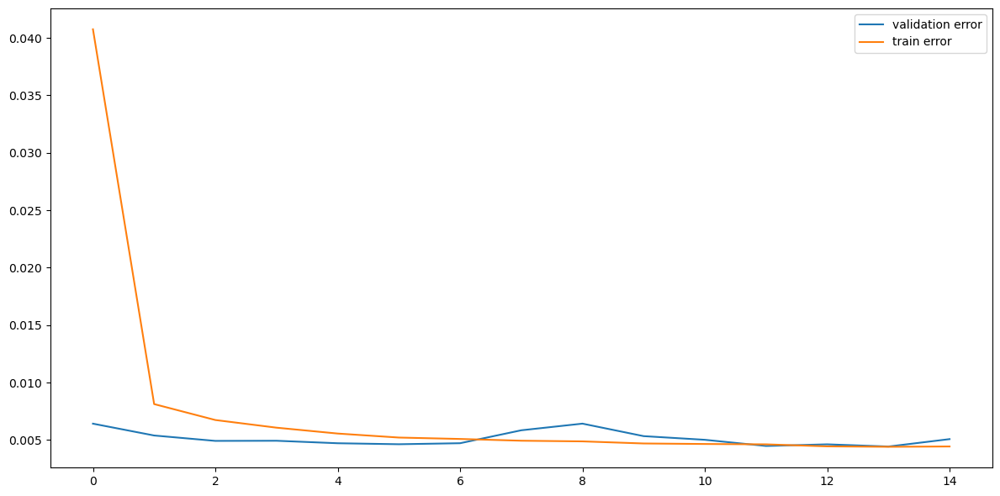

In [10]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-FI-reg-LOSS.pdf')
plt.show()

In [11]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/LSTM1-FI-best_model.pt', weights_only=False)

true = []
pred = []

torch.cuda.empty_cache()
# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-FI-reg-pryce.html')
fig.show()

In [12]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

7.8315675258636475
0.9986110545187733
0.034803133

9.923271834850311
0.9973819793138492
0.047761668

11.958519369363785
0.9955311793756294
0.06237374

15.415666997432709
0.991234973223752
0.087269664



optimized model:

In [19]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'hidden_layer_size': 128,
    'num_layers': 4,
    'output_size': y_train.shape[1],
    'dropout': 0.1
}
model = Models.LSTM1(**params).to(device)

# Define loss function and optimizer
learning_rate = 0.0001
epochs = 20
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info_tuned = utils.ModelTools.train(
    model_id = model.name + '-OPT',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/20 [00:00<?, ?it/s]

model saved
model saved
model saved
model saved
model saved


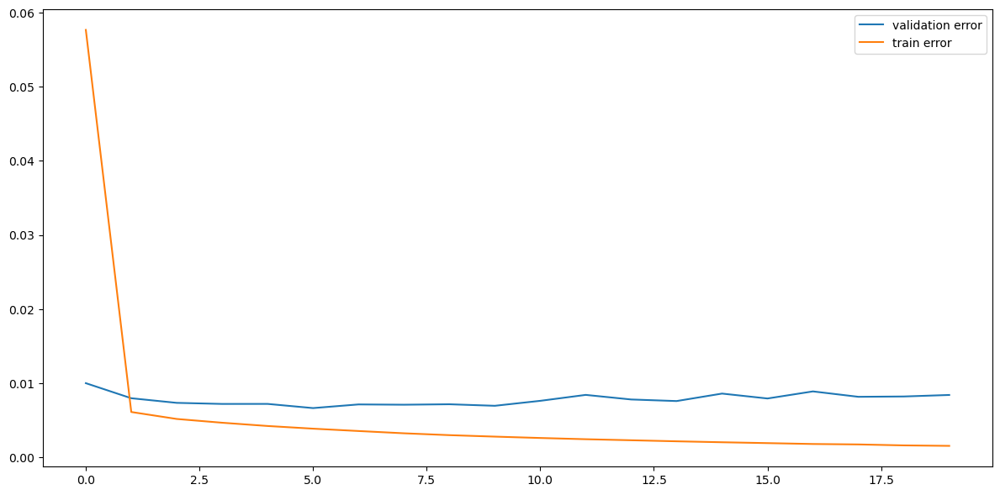

In [20]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info_tuned['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info_tuned['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-OPT-FI-reg-LOSS.pdf')
plt.show()

In [16]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-OPT-FI-best_model.pt', weights_only=False)

true = []
pred = []

torch.cuda.empty_cache()
# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-OPT-FI-reg-pryce.html')
fig.show()

In [17]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-OPT-FI-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-OPT-FI-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

8.191249519586563
0.9987230216811868
0.033370867

9.60669293999672
0.99788580240596
0.042920593

11.087707430124283
0.9968405337254462
0.05244598

13.731332123279572
0.9941841506311366
0.0710875



### Astice

In [17]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [18]:
# Create the model
params = {
    "input_size": X_train.shape[1],
    "output_size": y_train.shape[1],
    "hidden_size": 64,
    "lstm_size": 64,
    "lstm_layers": 2,
    "smooth_conv_channels": 32
}

model = Models.Astice(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved
model saved


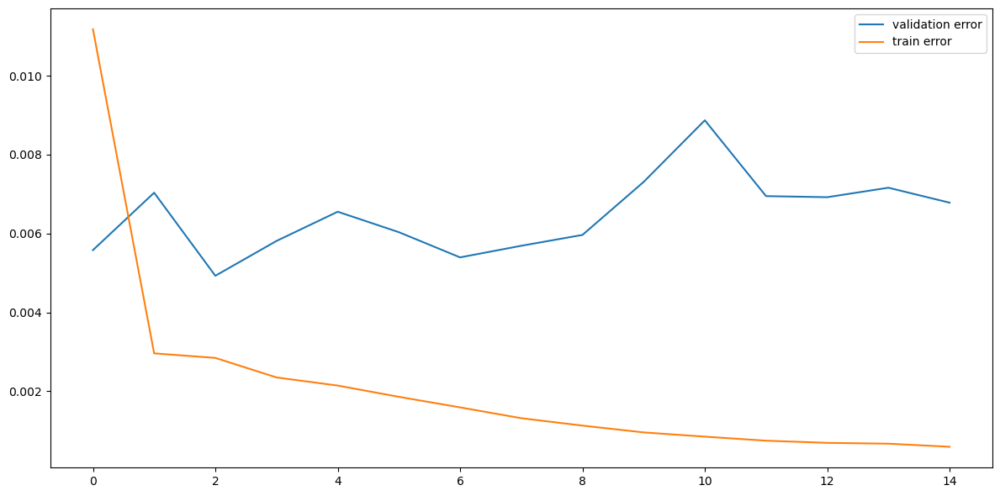

In [19]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-FI-reg-LOSS.pdf')
plt.show()

In [20]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-FI-best_model.pt', weights_only=False)

true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-FI-reg-pryce.html')
fig.show()

In [21]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

8.564000576734543
0.9985146567705403
0.035990603

9.88849252462387
0.9974068331054177
0.04753442

11.555607616901398
0.9955576841091791
0.0621885

14.94625210762024
0.991237151845699
0.08725882



optimized model:

In [9]:
# Create the model
params = {
    "input_size": X_train.shape[1],
    "output_size": y_train.shape[1],
    "hidden_size": 110,
    "lstm_size": 119,
    "lstm_layers": 2,
    "smooth_conv_channels": 32
}

model = Models.Astice(**params).to(device)

# Define loss function and optimizer
learning_rate = 1e-5
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info_tuned = utils.ModelTools.train(
    model_id = model.name + '-OPT',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved
model saved
model saved
model saved
model saved
model saved
model saved
model saved


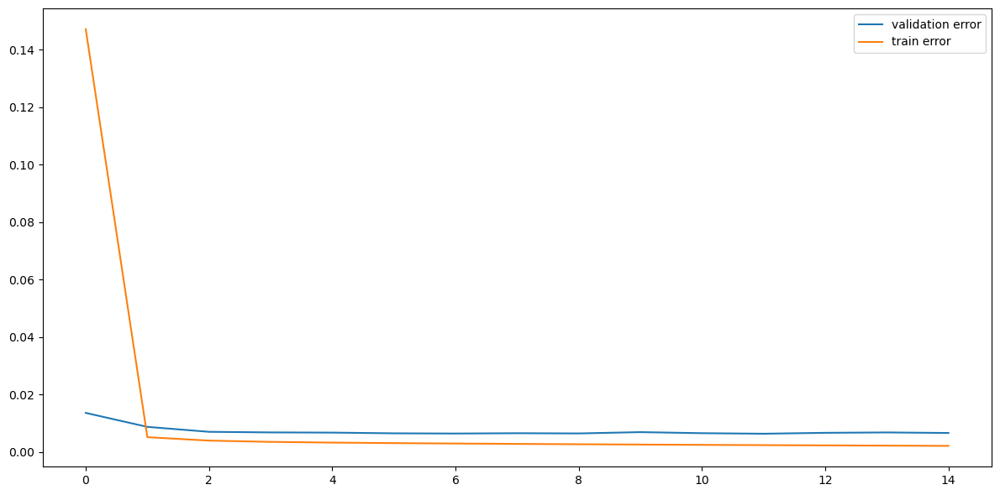

In [10]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info_tuned['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info_tuned['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-OPT-FI-reg-LOSS.pdf')
plt.show()

In [13]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-OPT-FI-best_model.pt', weights_only=False)

true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-OPT-FI-reg-pryce.html')
fig.show()

In [16]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-OPT-FI-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-OPT-FI-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

8.184181898832321
0.9980097373177245
0.041661117

9.537237882614136
0.9971333546546506
0.04997812

11.591603606939316
0.9955636302169781
0.06214686

14.720726013183594
0.9918726198566704
0.084035344



In [26]:
def plot_2_histories(history, history2, title, label_plot1, label_plot2):
    epochs = range(1, len(history) + 1)
    plt.plot(epochs, history, label=label_plot1)
    plt.plot(epochs, history2, label=label_plot2)
    plt.title(title)
    plt.xlabel('Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_3_histories(history1, history2, history3, title, label_plot1, label_plot2, label_plot3):
    epochs = range(1, len(history1) + 1)
    plt.plot(epochs, history1, label=label_plot1)
    plt.plot(epochs, history2, label=label_plot2)
    plt.plot(epochs, history3, label=label_plot3)
    plt.title(title)
    plt.xlabel('Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_4_histories(history1, history2, history3, history4, title, label_plot1, label_plot2, label_plot3, label_plot4):
    epochs = range(1, len(history1) + 1)
    plt.plot(epochs, history1, label=label_plot1)
    plt.plot(epochs, history2, label=label_plot2)
    plt.plot(epochs, history3, label=label_plot3)
    plt.plot(epochs, history4, label=label_plot4)
    plt.title(title)
    plt.xlabel('Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()

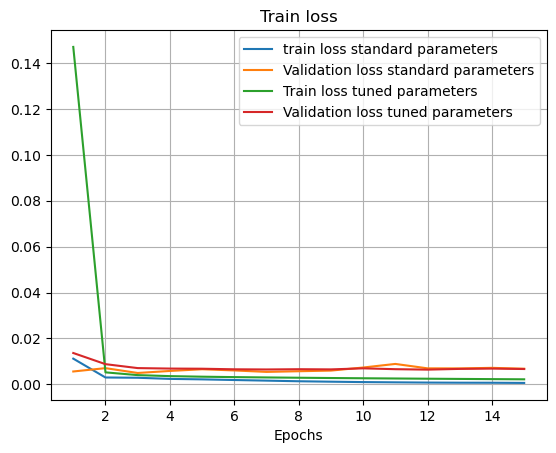

In [27]:
plot_4_histories(
    training_info['train_loss'],
    training_info['val_loss'],
    training_info_tuned['train_loss'],
    training_info_tuned['val_loss'],
    "Train loss",
    "train loss standard parameters",
    "Validation loss standard parameters",
    "Train loss tuned parameters",
    "Validation loss tuned parameters"
    )

### LobCNN

In [4]:
# in this case the predicted pryce is P_Ask_1
dataset = pd.read_parquet('/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/Data/FI-2010-Cleaned/NoAuction/MinMax/WRT1V.parquet')
dataset = dataset.drop(['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100', 'Day'], axis=1)
dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
dataset = dataset.astype(float)
dataset = dataset.head(100000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,0.962048,0.008123,0.964492,0.006633,0.962048,0.013564,0.964492,0.006650,0.961623,0.011154,...,0.019060,0.956217,0.004534,0.964476,0.004935,0.955381,0.002298,0.964048,0.025081,0.963270
1,0.961606,0.004041,0.964492,0.002583,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
2,0.961606,0.004041,0.964492,0.005917,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
3,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
4,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,0.976876,0.028329,0.977615,0.019617,0.976876,0.027472,0.977208,0.004183,0.976876,0.005157,...,0.004941,0.973769,0.004606,0.973545,0.031673,0.973769,0.010186,0.974338,0.003677,0.977246
99996,0.976876,0.028329,0.977615,0.022950,0.976876,0.019612,0.977208,0.004183,0.976876,0.005157,...,0.004397,0.973769,0.004606,0.975173,0.005180,0.973769,0.010186,0.974745,0.025127,0.977246
99997,0.976876,0.028329,0.977615,0.024617,0.976876,0.019612,0.977208,0.004183,0.976876,0.005157,...,0.004397,0.973769,0.004606,0.975173,0.005180,0.973769,0.010186,0.974745,0.025127,0.977246
99998,0.976876,0.028329,0.977615,0.024617,0.976876,0.019612,0.977208,0.004183,0.976876,0.005157,...,0.004941,0.973769,0.004606,0.973545,0.031673,0.973769,0.010186,0.974338,0.003677,0.977246


In [5]:
target_col = 'mid_price'
target_cols = []
shifts = [ 10, 20, 30, 50 ]

for shift in shifts:
    colname = f'Target_{shift}'
    target_cols.append(colname)
    dataset[colname] = dataset[target_col].shift(-shift)
dataset.dropna(inplace=True)

dataset = dataset.drop(['mid_price'], axis=1)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Target_10,Target_20,Target_30,Target_50
0,0.962048,0.008123,0.964492,0.006633,0.962048,0.013564,0.964492,0.006650,0.961623,0.011154,...,0.964476,0.004935,0.955381,0.002298,0.964048,0.025081,0.963268,0.964814,0.965259,0.966367
1,0.961606,0.004041,0.964492,0.002583,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963490,0.964373,0.965481,0.966367
2,0.961606,0.004041,0.964492,0.005917,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963490,0.964373,0.965481,0.966145
3,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963490,0.964817,0.965481,0.966367
4,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963490,0.964817,0.965481,0.966367
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99945,0.976876,0.036656,0.976801,0.013033,0.976876,0.019612,0.976801,0.006067,0.976876,0.005157,...,0.971103,0.003693,0.973366,0.004372,0.971079,0.018658,0.976839,0.976839,0.976839,0.977246
99946,0.976876,0.036656,0.976801,0.013033,0.976876,0.019612,0.976801,0.006067,0.976876,0.005157,...,0.971103,0.003693,0.973366,0.004372,0.971079,0.018658,0.976839,0.976839,0.976839,0.977246
99947,0.976876,0.036656,0.976801,0.013033,0.976876,0.019612,0.976801,0.006067,0.976876,0.005157,...,0.971103,0.003693,0.973366,0.004372,0.971079,0.018658,0.976839,0.976839,0.976839,0.977246
99948,0.976876,0.036656,0.976801,0.013033,0.976876,0.019612,0.976801,0.006067,0.976876,0.005157,...,0.972324,0.031673,0.973366,0.004372,0.972301,0.002929,0.976839,0.976839,0.976839,0.977246


In [6]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
scaler = preprocessing.StandardScaler()
scaler.fit(dataset_train)
dataset_train[dataset_train.columns] = scaler.transform(dataset_train)
dataset_val[dataset_val.columns] = scaler.transform(dataset_val)
dataset_test[dataset_test.columns] = scaler.transform(dataset_test)

#means = dataset_train.mean(axis=0)
#stds = dataset_train.std(axis=0)
#
#means[-len(target_cols):] = means[target_cols]
#stds[-len(target_cols):] = stds[target_cols]
#
#dataset_train = ( dataset_train - means ) / stds
#dataset_val = ( dataset_val - means ) / stds
#dataset_test = ( dataset_test - means ) / stds

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Target_10,Target_20,Target_30,Target_50
0,-0.103890,-0.568381,-0.083300,-0.045714,-0.109613,-0.449856,-0.076872,-0.095413,-0.119713,-0.512336,...,-0.036927,-0.655501,-0.185020,-0.799786,-0.040749,0.932110,-0.093417,-0.055289,-0.044134,-0.016523
1,-0.114683,-0.768915,-0.083300,-0.617532,-0.120403,-0.449856,-0.076872,-0.568218,-0.130536,-0.512336,...,-0.026096,0.411839,-0.217770,1.647943,-0.019004,-0.594323,-0.087979,-0.066101,-0.038698,-0.016523
2,-0.114683,-0.768915,-0.083300,-0.146900,-0.120403,-0.449856,-0.076872,-0.568218,-0.130536,-0.512336,...,-0.026096,0.411839,-0.217770,1.647943,-0.019004,-0.594323,-0.087979,-0.066101,-0.038698,-0.021957
3,-0.114683,-0.768915,-0.083300,-0.542231,-0.120403,-0.449856,-0.076872,-0.095413,-0.130536,-0.512336,...,-0.026096,0.411839,-0.217770,1.647943,-0.019004,-0.594323,-0.087979,-0.055226,-0.038698,-0.016523
4,-0.114683,-0.768915,-0.083300,-0.542231,-0.120403,-0.449856,-0.076872,-0.095413,-0.130536,-0.512336,...,-0.026096,0.411839,-0.217770,1.647943,-0.019004,-0.594323,-0.087979,-0.055226,-0.038698,-0.016523
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69960,-1.750619,0.364106,-1.764453,-0.297502,-1.755945,-0.642236,-1.758141,0.850195,-1.761306,-0.646376,...,-1.787014,-0.840064,-1.796883,1.403204,-1.779943,-0.741229,-1.752419,-1.726686,-1.726079,-1.734881
69961,-1.750619,0.765175,-1.774544,0.897903,-1.755945,-0.642236,-1.768232,-0.095413,-1.761306,-0.646376,...,-1.807064,-0.754455,-1.776545,-0.641456,-1.810172,-0.807767,-1.747383,-1.726686,-1.726079,-1.734881
69962,-1.750619,-0.167311,-1.774544,0.897903,-1.755945,-0.642236,-1.768232,-0.095413,-1.761306,-0.646376,...,-1.787014,-0.840064,-1.776545,-0.641456,-1.779943,-0.741229,-1.747383,-1.726686,-1.726079,-1.734881
69963,-1.750619,-0.568381,-1.774544,0.897903,-1.755945,-0.642236,-1.768232,-0.095413,-1.761306,-0.646376,...,-1.787014,-0.840064,-1.776545,-0.641456,-1.779943,-0.741229,-1.747383,-1.726686,-1.726079,-1.734881


In [7]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, target_cols)
X_val, y_val = utils.DataTools.split_x_y(dataset_val, target_cols)
X_test, y_test = utils.DataTools.split_x_y(dataset_test, target_cols)

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 128,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 69766 samples
Test dataset: 14794 samples


In [8]:
true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    #print(features.shape)
    for i in range(len(shifts)):
        pred.append(features[:, :, -1, 0].numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print("dummy regressor: last value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "   ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))


true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    for i in range(len(shifts)):
        pred.append(np.mean(features[:, :, :, 0].numpy(), axis=2))

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print()
print("dummy regressor: mean value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "   ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))

dummy regressor: last value

10        sMAPE:  9.302673488855362     RMSE:  0.037547816
20        sMAPE:  9.535716474056244     RMSE:  0.03892052
30        sMAPE:  9.786062687635422     RMSE:  0.041225124
50        sMAPE:  10.821233689785004     RMSE:  0.0467356

dummy regressor: mean value

10        sMAPE:  10.751402378082275     RMSE:  0.045145936
20        sMAPE:  11.406953632831573     RMSE:  0.048325423
30        sMAPE:  12.048983573913574     RMSE:  0.051695272
50        sMAPE:  13.859154284000397     RMSE:  0.05883598


In [33]:
dataloader_train.dataset.channels = True
dataloader_val.dataset.channels = True
dataloader_test.dataset.channels = True

In [81]:
# Create the model

params = {
    "vertical_convolutional_layers" : 2,
    "vertical_kernel_size" : 4,
    "smoothing" : False,
    "convolution_channels" : 32,
    "inception_channels" : 64,
    "lstm_layers" : 2,
    "latent_size" : 64,
    "dropout" : 0.2,
    "output_size" : y_train.shape[1],
}

model = Models.LobCNN(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 10
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/10 [00:00<?, ?it/s]

model saved
model saved
model saved


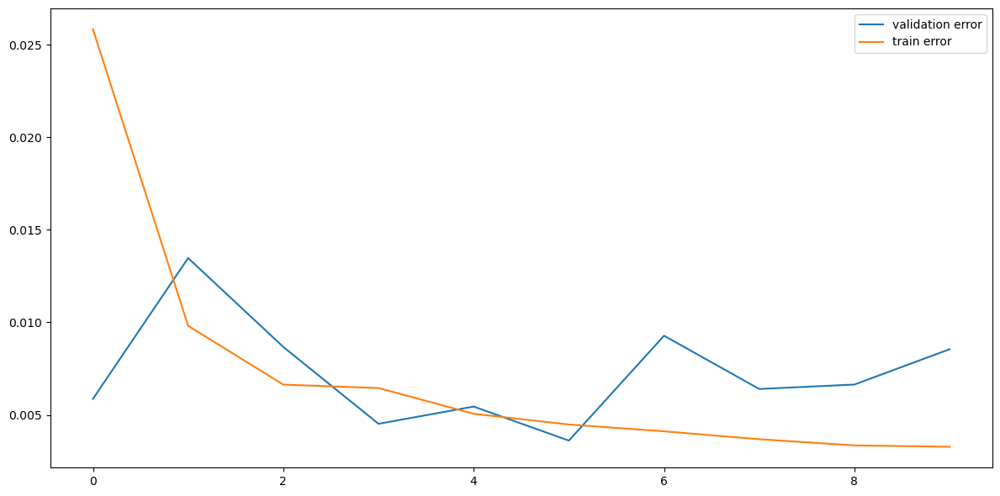

In [83]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-FI-reg-LOSS.pdf')
plt.show()

In [84]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-FI-best_model.pt', weights_only=False)

true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-FI-reg-pryce.html')
fig.show()

In [86]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

13.072487711906433
0.9860090326278846
0.06295855

13.604456186294556
0.9852224743227772
0.06467517

14.595595002174377
0.9842078539623835
0.06682796

15.731291472911835
0.9816194094847867
0.07202328



optimized model:

In [35]:
# Create the model

params = {
    "vertical_convolutional_layers" : 2,
    "vertical_kernel_size" : 4,
    "smoothing" : False,
    "convolution_channels" : 32,
    "inception_channels" : 64,
    "lstm_layers" : 2,
    "latent_size" : 91,
    "dropout" : 0.14703987403582064,
    "output_size" : y_train.shape[1],
}

model = Models.LobCNN(**params).to(device)

# Define loss function and optimizer
learning_rate = 0.004425003913286585
epochs = 10
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info_tuned = utils.ModelTools.train(
    model_id = model.name + '-OPT',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/10 [00:00<?, ?it/s]

model saved
model saved
model saved


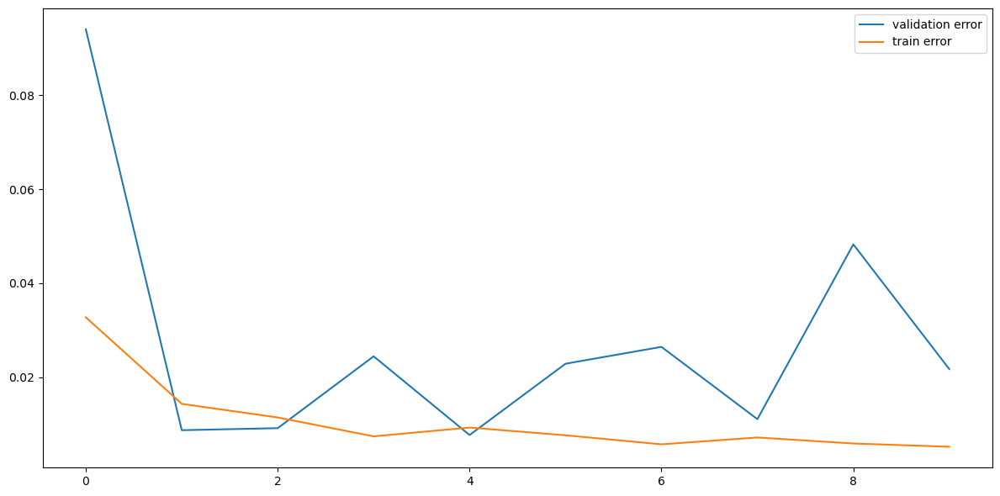

In [36]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info_tuned['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info_tuned['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-OPT-FI-reg-LOSS.pdf')
plt.show()

In [37]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-OPT-FI-best_model.pt', weights_only=False)

true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-OPT-FI-reg-pryce.html')
fig.show()

In [38]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-OPT-FI-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-OPT-FI-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

16.388657689094543
0.9644734749576442
0.100324556

17.448344826698303
0.960387686144818
0.10588923

18.567658960819244
0.9564811269862612
0.11093701

19.839879870414734
0.9522732246183085
0.11605776



### LSTM seq-to-seq with Attention

In [58]:
dataset = pd.read_parquet('/home/joel/Desktop/DSSC/DEEP_LEARNING/Data/FI-2010/NoAuction/MinMax/WRT1V.parquet')
dataset = dataset.astype(float)
dataset = dataset.drop(['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100', 'Day'], axis=1)
dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
dataset = dataset.head(100000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,0.962048,0.008123,0.964492,0.006633,0.962048,0.013564,0.964492,0.006650,0.961623,0.011154,...,0.019060,0.956217,0.004534,0.964476,0.004935,0.955381,0.002298,0.964048,0.025081,0.963270
1,0.961606,0.004041,0.964492,0.002583,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
2,0.961606,0.004041,0.964492,0.005917,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
3,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
4,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,0.976876,0.028329,0.977615,0.019617,0.976876,0.027472,0.977208,0.004183,0.976876,0.005157,...,0.004941,0.973769,0.004606,0.973545,0.031673,0.973769,0.010186,0.974338,0.003677,0.977246
99996,0.976876,0.028329,0.977615,0.022950,0.976876,0.019612,0.977208,0.004183,0.976876,0.005157,...,0.004397,0.973769,0.004606,0.975173,0.005180,0.973769,0.010186,0.974745,0.025127,0.977246
99997,0.976876,0.028329,0.977615,0.024617,0.976876,0.019612,0.977208,0.004183,0.976876,0.005157,...,0.004397,0.973769,0.004606,0.975173,0.005180,0.973769,0.010186,0.974745,0.025127,0.977246
99998,0.976876,0.028329,0.977615,0.024617,0.976876,0.019612,0.977208,0.004183,0.976876,0.005157,...,0.004941,0.973769,0.004606,0.973545,0.031673,0.973769,0.010186,0.974338,0.003677,0.977246


In [59]:
target_col = 'mid_price'
target_cols = []
shifts = [ 0 ]

for shift in shifts:
    colname = f'Target_{shift}'
    target_cols.append(colname)
    dataset[colname] = dataset[target_col].shift(-shift)
dataset.dropna(inplace=True)

In [60]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
scaler = preprocessing.StandardScaler()
scaler.fit(dataset_train)

dataset_train[dataset_train.columns] = scaler.fit_transform(dataset_train)
dataset_val[dataset_val.columns] = scaler.fit_transform(dataset_val)
dataset_test[dataset_test.columns] = scaler.fit_transform(dataset_test)

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_0
0,-0.102978,-0.568266,-0.082383,-0.045614,-0.108698,-0.449783,-0.075962,-0.095640,-0.118794,-0.512488,...,-0.162501,-0.660291,-0.036043,-0.655515,-0.184049,-0.799813,-0.039858,0.932501,-0.092728,-0.092728
1,-0.113765,-0.768828,-0.082383,-0.617555,-0.119483,-0.449783,-0.075962,-0.568532,-0.129611,-0.512488,...,-0.205455,-0.626493,-0.025218,0.412000,-0.216782,1.648069,-0.018124,-0.594119,-0.098134,-0.098134
2,-0.113765,-0.768828,-0.082383,-0.146822,-0.119483,-0.449783,-0.075962,-0.568532,-0.129611,-0.512488,...,-0.205455,-0.626493,-0.025218,0.412000,-0.216782,1.648069,-0.018124,-0.594119,-0.098134,-0.098134
3,-0.113765,-0.768828,-0.082383,-0.542238,-0.119483,-0.449783,-0.075962,-0.095640,-0.129611,-0.512488,...,-0.205455,-0.626493,-0.025218,0.412000,-0.216782,1.648069,-0.018124,-0.594119,-0.098134,-0.098134
4,-0.113765,-0.768828,-0.082383,-0.542238,-0.119483,-0.449783,-0.075962,-0.095640,-0.129611,-0.512488,...,-0.205455,-0.626493,-0.025218,0.412000,-0.216782,1.648069,-0.018124,-0.594119,-0.098134,-0.098134
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,-1.728869,-0.768828,-1.742503,-0.132700,-1.724185,-0.439394,-1.736205,0.478925,-1.729442,-0.646528,...,-1.747221,0.819890,-1.745176,-0.674570,-1.774751,-0.641473,-1.758027,-0.470420,-1.736202,-1.736202
69996,-1.728869,-0.768828,-1.742503,-0.132700,-1.724185,-0.439394,-1.736205,0.478925,-1.729442,-0.646528,...,-1.737227,-0.637845,-1.745176,-0.674570,-1.764587,-0.689228,-1.758027,-0.470420,-1.736202,-1.736202
69997,-1.728869,-0.768828,-1.742503,-0.132700,-1.724185,-0.510497,-1.736205,0.478925,-1.729442,-0.646528,...,-1.737227,-0.637845,-1.745176,-0.674570,-1.764587,-0.689228,-1.758027,-0.470420,-1.736202,-1.736202
69998,-1.748897,-0.768828,-1.742503,-0.132700,-1.724185,-0.510497,-1.736205,-0.568532,-1.729442,-0.646528,...,-1.727232,-0.690942,-1.745176,-0.674570,-1.754423,-0.606742,-1.758027,-0.470420,-1.746238,-1.746238


In [61]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, ['mid_price'])
X_val, y_val = utils.DataTools.split_x_y(dataset_val, ['mid_price'])
X_test, y_test = utils.DataTools.split_x_y(dataset_test, ['mid_price'])

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
seq_len_y = 51
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = seq_len_y,
    offset    = lookback_period,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = seq_len_y,
    offset    = lookback_period,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = seq_len_y,
    offset    = lookback_period,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 69800 samples
Test dataset: 14800 samples


In [62]:
true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.squeeze().numpy())
    pred_prov = []
    for i in range(seq_len_y):
        pred_prov.append(features[:, -1, 0])
        catt = torch.stack(pred_prov, axis=1)
    pred.append(catt)


true = np.concatenate(true, axis=0)
true = true.reshape(len(true), seq_len_y)
pred = torch.cat(pred, axis=0).numpy()

print(true.shape)
print(pred.shape)

sMAPEs = []
RMSEs  = []


for i in range(pred.shape[0]):
    sMAPEs.append(utils.Metrics.sMAPE(true[i, :], pred[i, :]))
    RMSEs.append(root_mean_squared_error(true[i, :], pred[i, :]))

print("dummy regressor: last value")
print()
print("sMAPE mean: ", np.mean(sMAPEs), "   ", "RMSE mean: ", np.mean(RMSEs))

(14800, 51)
(14800, 51)
dummy regressor: last value

sMAPE mean:  7.158735183877807     RMSE mean:  0.045752723


In [63]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [53]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'output_size': y_train.shape[1],
    'encoder_hidden_size': 100,
    'decoder_hidden_size': 100,
    'num_layers': 2,
    'dropout': 0.15
}

model = Models.LSTMSeq2SeqAttention(**params).to(device)

# Define loss function and optimizer
learning_rate = 1e-4
epochs = 10
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train_seq_to_seq(
    model_id = model.name,
    model = model,
    teacher_forcing_ratio = 0.5,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = False,
    device = model.device
)

Training:   0%|          | 0/10 [00:00<?, ?it/s]

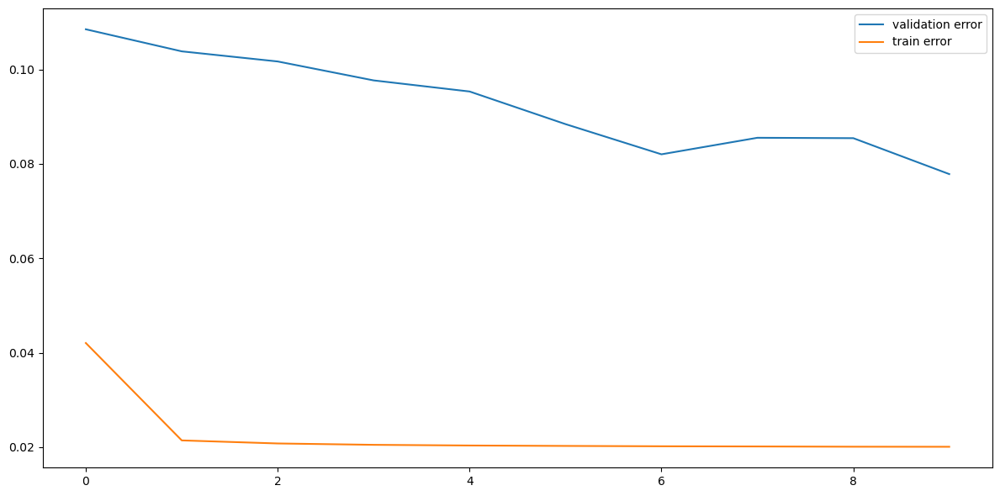

In [55]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-FI-reg-LOSS.pdf')
plt.show()

In [57]:
#best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-FI-best_model.pt', weights_only=False)

shifts = [ 10, 20, 30, 50 ]

fig = make_subplots(rows=len(shifts), cols=1)

# Evaluate the model
for i in range(len(shifts)):
    true = []
    pred = []
    with torch.no_grad():
        for inputs, labels in dataloader_test:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs, labels, teacher_forcing_ratio=0.)
            true.append(labels[:,shifts[i],:].cpu().numpy())
            pred.append(outputs[:,shifts[i],:].cpu().numpy())
    
    true = np.concatenate(true)#.reshape(-1, y_train.shape[1])
    pred = np.concatenate(pred)#.reshape(-1, y_train.shape[1])

    print(utils.Metrics.sMAPE(true[:], pred[:]))
    print(r2_score(true[:], pred[:]))
    print(root_mean_squared_error(true[:], pred[:]))
    print()
    
    fig.add_scatter(x=np.arange(len(true)), y=true.flatten(), mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(x=np.arange(len(pred)), y=pred.flatten(), mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {shifts}", xaxis_title = "Time", yaxis_title = "Price", height=1600)

#fig.write_html(f'./figures/{model.name}-FI-reg-pryce.html')
fig.show()

7.475960999727249
0.9966627873726005
0.057369366

10.594358295202255
0.9933605315983782
0.08090063

13.40605765581131
0.9895649177843072
0.10139721

17.35372245311737
0.98266827202924
0.13059908



optimized model:

In [15]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'output_size': y_train.shape[1],
    'encoder_hidden_size': 100,
    'decoder_hidden_size': 100,
    'num_layers': 4,
    'dropout': 0.1803
}

model = Models.LSTMSeq2SeqAttention(**params).to(device)

# Define loss function and optimizer
learning_rate = 3.038e-05
epochs = 10
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info_tuned = utils.ModelTools.train_seq_to_seq(
    model_id = model.name + '-OPT-50k',
    model = model,
    teacher_forcing_ratio = 0.5,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/10 [00:00<?, ?it/s]

model saved
model saved
model saved
model saved
model saved
model saved
model saved
model saved
model saved


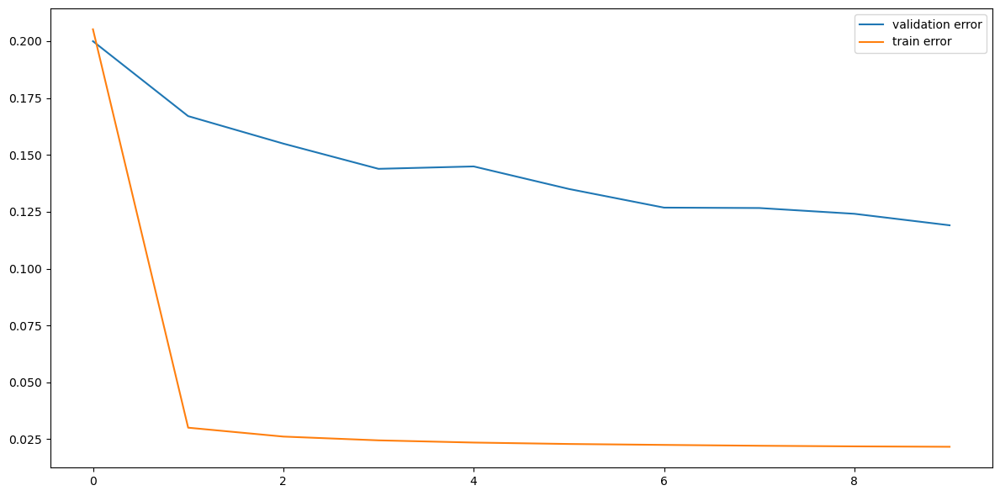

In [16]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info_tuned['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info_tuned['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.show()

In [64]:
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/LSTM-seq-to-seq-wAttention.pt', weights_only=False)

shifts = [ 10, 20, 30, 40, 50 ]

fig = make_subplots(rows=len(shifts), cols=1)
m = 0
# Evaluate the model
for i in range(len(shifts)):
    true = []
    pred = []
    with torch.no_grad():
        for inputs, labels in dataloader_test:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = best_model(inputs, labels, teacher_forcing_ratio=0.)
            true.append(labels[:,shifts[i],:].cpu().numpy())
            pred.append(outputs[:,shifts[i],:].cpu().numpy())
    
    true = np.concatenate(true)#.reshape(-1, y_train.shape[1])
    pred = np.concatenate(pred)#.reshape(-1, y_train.shape[1])
    
    fig.add_scatter(x=np.arange(len(true)), y=true.flatten(), mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(x=np.arange(len(pred)), y=pred.flatten(), mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {shifts}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
    m = m + utils.Metrics.sMAPE(true[:], pred[:])
    print(utils.Metrics.sMAPE(true[:], pred[:]))
    print(r2_score(true[:], pred[:]))
    print(root_mean_squared_error(true[:], pred[:]))
    print()

print(m)
fig.write_html(f'./figures/{best_model.name}-OPT-DEF-FI-reg-pryce.html')
fig.show()


6.745213270187378
0.997375036168271
0.050841674

8.525203168392181
0.9955615475479632
0.06608838

10.328098386526108
0.9932322846329888
0.081581555

12.247531861066818
0.9903817783482503
0.09722785

14.173457026481628
0.9869708599935363
0.1131306

52.019503712654114


In [41]:
true = []
pred = []
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs, labels, teacher_forcing_ratio=0.)
        true.append(labels.squeeze().cpu().numpy())
        pred.append(outputs.squeeze().cpu().numpy())


true = np.concatenate(true, axis=0)
#true = true.reshape(len(true), seq_len_y)

pred = np.concatenate(pred, axis=0)
#pred = pred.reshape(len(pred), seq_len_y)

print(true.shape)
print(pred.shape)

sMAPEs = []
RMSEs  = []


for i in range(pred.shape[0]):
    sMAPEs.append(utils.Metrics.sMAPE(true[i, :], pred[i, :]))
    RMSEs.append(root_mean_squared_error(true[i, :], pred[i, :]))

print("dummy regressor: last value")
print()
print("sMAPE mean: ", np.mean(sMAPEs), "   ", "RMSE mean: ", np.mean(RMSEs))

(14800, 51)
(14800, 51)
dummy regressor: last value

sMAPE mean:  13.367133402844539     RMSE mean:  0.14805132


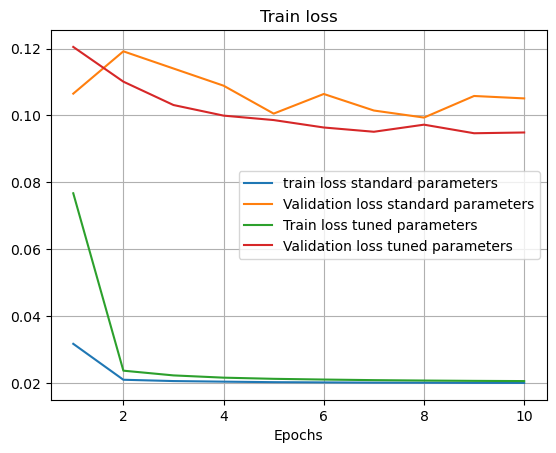

In [ ]:
plot_4_histories(
    training_info['train_loss'],
    training_info['val_loss'],
    training_info_tuned['train_loss'],
    training_info_tuned['val_loss'],
    "Train loss",
    "train loss standard parameters",
    "Validation loss standard parameters",
    "Train loss tuned parameters",
    "Validation loss tuned parameters"
    )